# Fig. S4 — Single-treatment dose response and regime-transition doses
Final leader fraction $x(T)$ (left) and population reduction $R_N(T)$ (right) against dose at $T = 15$ days
for each single-entry perturbation; dotted lines mark the regime-transition doses $d^*$ (Table 2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

Snowdrift            beta  d* = 0.25 -> Prisoner's Dilemma


Snowdrift            gamma d* = 0.50 -> Harmony


Harmony              alpha d* = 0.50 -> Snowdrift


Harmony              beta  d* = 0.25 -> Coordination


Coordination         alpha d* = 0.50 -> Prisoner's Dilemma


Coordination         delta d* = 0.67 -> Harmony


Prisoner's Dilemma   gamma d* = 0.50 -> Coordination


Prisoner's Dilemma   delta d* = 0.67 -> Snowdrift


Saved ../figures/FigS4_single_treatment_dose_response.png/.pdf


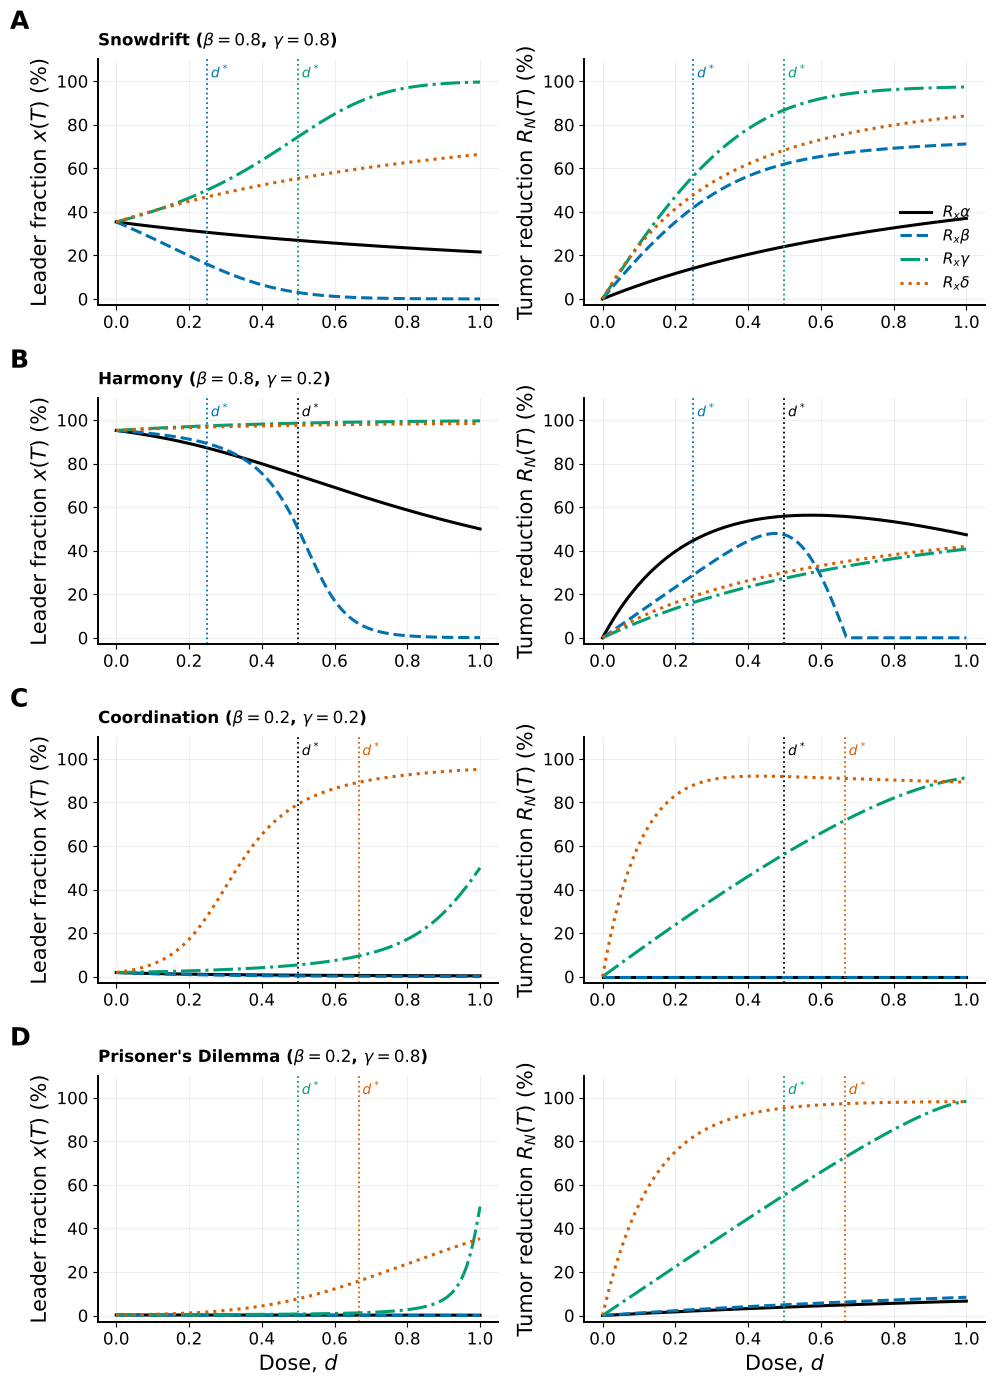

In [2]:
d = np.linspace(0, 1, 201)
fig, axes = plt.subplots(4, 2, figsize=(10, 14))
for row, (name, (b, gm)) in enumerate(REGIMES.items()):
    axx, axr = axes[row]
    for tg in TARGETS:
        r_n, s_l, J, x_t = treatment_outcome(b, gm, {tg: d}, T=15.0)
        for ax, y in ((axx, 100 * x_t), (axr, np.clip(r_n, 0, 100))):
            ax.plot(d, y, TARGET_STYLE[tg], color=TARGET_COLOR[tg], lw=2.2, label=TARGET_LABEL[tg])
        ds = crossing_dose(tg, ALPHA, b, gm, DELTA)
        if not np.isnan(ds):
            new = regime_name(*perturbed(b, gm, {tg: ds + 1e-6}))
            print(f"{name:20s} {tg:5s} d* = {ds:.2f} -> {new}")
            for ax in (axx, axr):
                ax.axvline(ds, color=TARGET_COLOR[tg], ls=":", lw=1.3)
            for ax in (axx, axr):
                ax.text(ds + 0.01, 104, r"$d^*$", color=TARGET_COLOR[tg], ha="left", va="center", fontsize=10)
    axx.set_ylabel("Leader fraction $x(T)$ (%)"); axr.set_ylabel("Tumor reduction $R_N(T)$ (%)")
    for ax in (axx, axr):
        ax.set_ylim(-3, 110)
    axx.set_title(f"{name} ($\\beta={b}$, $\\gamma={gm}$)", fontweight="bold", loc="left", fontsize=12, pad=10)
    for ax in (axx, axr):
        ax.grid(alpha=0.2)
    panel_letter(axx, "ABCD"[row], x=-0.22, y=1.1)
for ax in axes[-1]:
    ax.set_xlabel("Dose, $d$")
axes[0, 1].legend(loc="lower right", frameon=False)
fig.tight_layout()
save(fig, "FigS4_single_treatment_dose_response")
plt.show()